##Ukázka jiného přístupu k tvorbě znalostí

###Použití neuronové sítě
1.  pomocí neuronové sítě vytvoříme model.
2.  Z modelu vytvoříme konfuzní tabulku

In [37]:
# Importy
import os
import librosa
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.cluster.hierarchy import dendrogram, linkage
from scipy.spatial.distance import pdist, squareform

In [ ]:
# Cesta ke slozce s daty
data_path = r'related_path_to_your_data_folder'

In [39]:
# Nacteni priznaku ze vsech nahravek v dane slozce
speech_features = []

# Prochazeni vsech souboru ve slozce
for file in os.listdir(data_path):
    file_path = os.path.join(data_path, file)

    # Nacteni zvukoveho souboru
    y, sr = librosa.load(file_path, sr=None)

    # Extrahovani priznaku z nahravky (mel-frekvencni spektrogram)
    mel_spec = librosa.feature.melspectrogram(y=y, sr=sr)

    # Pridnai priznaku do seznamu
    speech_features.append(mel_spec)

    # Vypis rozmeru nactenych priznaku pro kazdou nahravku
    print(f"Rozmery priznaku pro soubor {file}: {mel_spec.shape}")

Rozmery priznaku pro soubor AB_bonafide(M).wav: (128, 213)
Rozmery priznaku pro soubor AB_spoof(M).wav: (128, 263)
Rozmery priznaku pro soubor DD_bonafide(Z).wav: (128, 100)
Rozmery priznaku pro soubor DD_spoof(Z).wav: (128, 180)
Rozmery priznaku pro soubor JB_bonafide(Z).wav: (128, 131)
Rozmery priznaku pro soubor JB_spoof(Z).wav: (128, 76)
Rozmery priznaku pro soubor JMo_bonafide(Z).wav: (128, 185)
Rozmery priznaku pro soubor JMo_spoof(Z).wav: (128, 39)
Rozmery priznaku pro soubor KG_bonafide(M).wav: (128, 177)
Rozmery priznaku pro soubor KG_spoof(M).wav: (128, 161)
Rozmery priznaku pro soubor KS_bonafide(M).wav: (128, 254)
Rozmery priznaku pro soubor KS_spoof(M).wav: (128, 90)
Rozmery priznaku pro soubor LB_bonafide(Z).wav: (128, 56)
Rozmery priznaku pro soubor LB_spoof(Z).wav: (128, 31)
Rozmery priznaku pro soubor LV_bonafide(Z).wav: (128, 194)
Rozmery priznaku pro soubor LV_spoof(Z).wav: (128, 159)
Rozmery priznaku pro soubor PF_bonafide(M).wav: (128, 185)
Rozmery priznaku pro sou

In [40]:
# Zvoleni spolecne delky (maximalni delku ze vsech nahravek)
max_length = max(feature.shape[1] for feature in speech_features)

# Normalizace priznaku (kratsi na delsi, delsi na kratsi)
padded_speech_features = [np.pad(feature, ((0, 0), (0, max_length - feature.shape[1])), mode='constant') for feature in speech_features]

# Spojeni priznaku do jednoho pole
all_features = np.array(padded_speech_features).reshape(len(padded_speech_features), -1)

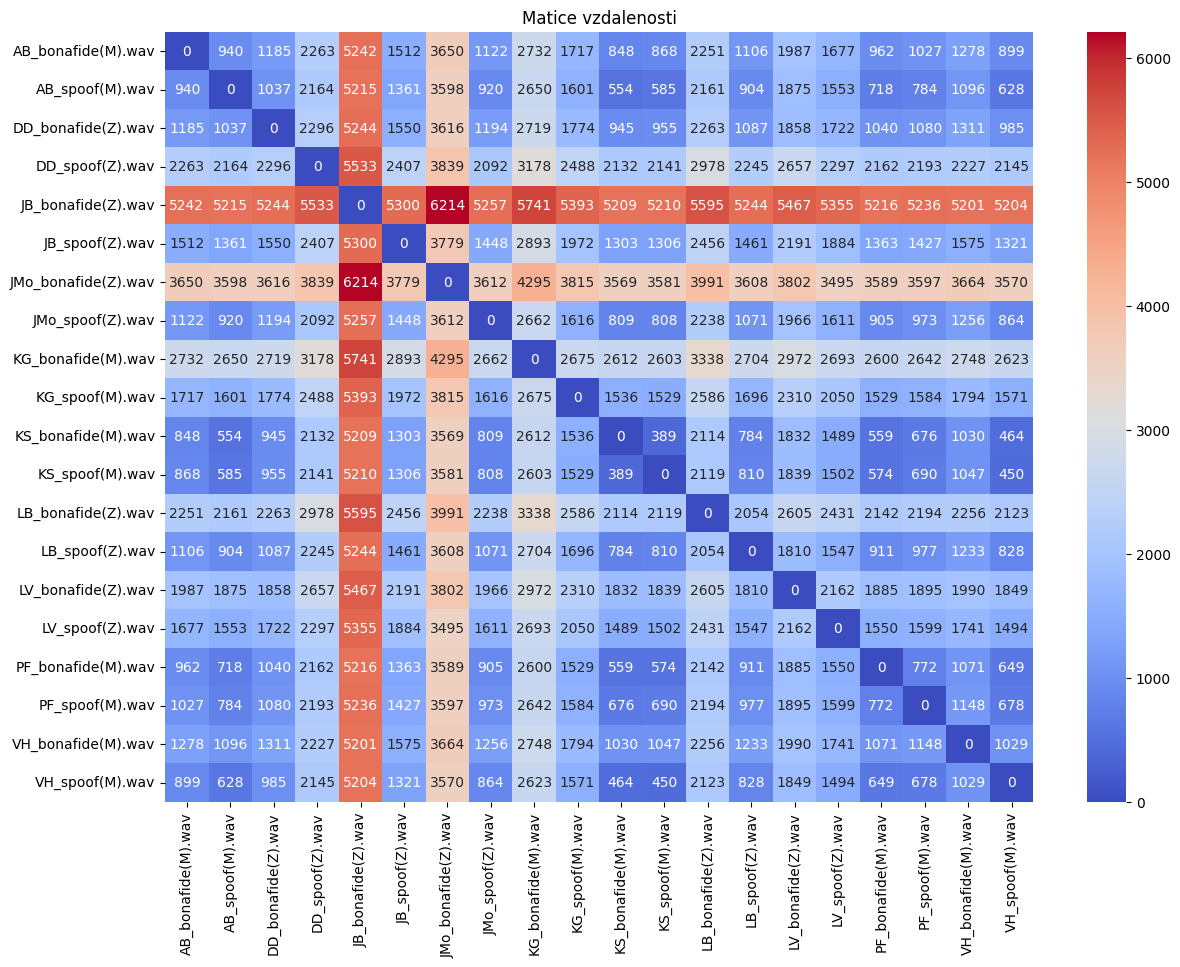

In [41]:
# Vytvoreni matice vzdalenosti
distance_matrix = squareform(pdist(all_features))

# Nacteni nazvu souboru
file_names = os.listdir(data_path)

# Zobrazeni matice vzdalenosti pomoci teplotni mapy
plt.figure(figsize=(14, 10))
sns.heatmap(distance_matrix, annot=True, fmt=".0f", cmap="coolwarm",
            xticklabels=file_names, yticklabels=file_names)
plt.title("Matice vzdalenosti")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.show()

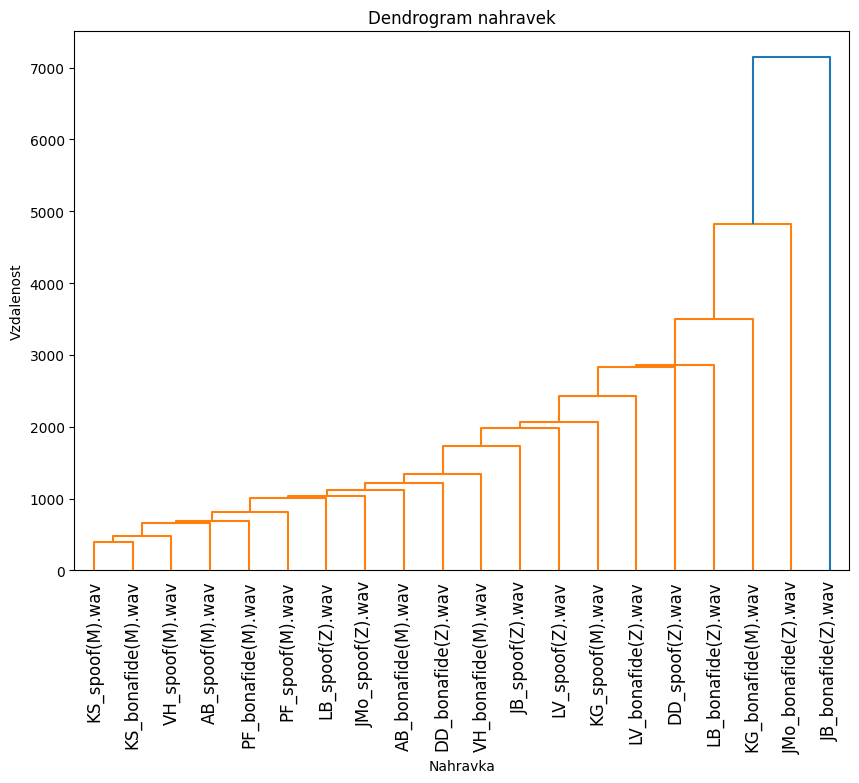

In [42]:
# Prepocitani matice vzdalenosti pro zobrazeni dendogramu
distance_matrix = pdist(all_features)

# Vytvoreni dendrogramu
linked = linkage(distance_matrix, 'ward')

# Vykresleni dendrogramu
plt.figure(figsize=(10, 7))
dendrogram(linked,
           orientation = 'top',
           labels = file_names,
           distance_sort = 'descending',
           show_leaf_counts = True)
plt.title('Dendrogram nahravek')
plt.xlabel('Nahravka')
plt.ylabel('Vzdalenost')
plt.xticks(rotation=90)
plt.show()